# 03 · Modelamiento: modelo jerárquico y colinealidad

**Proyecto semestral IMT2200, Grupo 5:** *¿Mide el NEM lo mismo para todos?*

**Entrada:** `data/processed/muestra.parquet` (de `02_eda`). Colinealidad, modelo
jerárquico, ICC e Hipótesis 1. Todos los resultados son **asociaciones**, no
efectos causales.

In [1]:
# Librerías, funciones del proyecto (src/) y carga de datos.
import sys
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import statsmodels.formula.api as smf
from patsy import dmatrix
from statsmodels.stats.outliers_influence import variance_inflation_factor

sys.path.insert(0, '..')  # para importar src/ desde notebooks/
from src.funciones import (coeficientes, contraste, icc,  # noqa: E402
                           mostrar, preparar_datos)

datos = preparar_datos(pd.read_parquet('../data/processed/muestra.parquet'))

## 1. Datos del modelo

Se usa la muestra analítica completa más la **composición socioeconómica del
colegio**: el decil medio de sus estudiantes (4 años juntos), solo con quienes
declaran ingreso. Hay 4 estudiantes que son los únicos de su colegio y no declaran
ingreso; su colegio no tiene decil medio, así que se excluyen de todos los modelos
para que todos usen los mismos estudiantes.

In [2]:
# 1. Deja fuera a los estudiantes cuyo colegio no tiene decil medio.
sin_composicion = datos['decil_medio_colegio'].isna()
datos = datos[~sin_composicion]
print(f'Excluidos por no tener decil medio del colegio: '
      f'{sin_composicion.sum()}')
print(f"Datos del modelo: {len(datos)} estudiantes en "
      f"{datos['RBD'].nunique()} colegios")

Excluidos por no tener decil medio del colegio: 4
Datos del modelo: 654138 estudiantes en 3030 colegios


## 2. Colinealidad (VIF)

El **VIF** mide cuánto aumenta la varianza de un coeficiente porque esa variable se
puede predecir con las demás. Un VIF de 1 indica que no se solapa con ninguna; los
umbrales habituales de alerta son 5 o 10. Cada variable categórica aporta una
columna por categoría (salvo la de referencia).

In [3]:
# 2. VIF de cada columna de la matriz de diseño (sin el intercepto).
# Referencias: Part. subvencionado, decil 1, Hombre, Científico-humanista
# y 2023.
def vif(variables: str) -> pd.Series:
    matriz = dmatrix(variables, datos, return_type='dataframe')
    valores = []
    for i in range(1, matriz.shape[1]):
        valores.append(variance_inflation_factor(matriz.values, i))
    return pd.Series(valores, index=matriz.columns[1:]).round(2)


VARIABLES = 'PAES_z + dependencia + decil + sexo + modalidad + C(ANIO)'
tabla_vif = vif(VARIABLES)
print(f'VIF máximo: {tabla_vif.max():.2f}')
display(tabla_vif.to_frame('VIF'))

VIF máximo: 2.13


,VIF
dependencia[T.Adm. delegada],1.15
dependencia[T.Municipal],1.14
dependencia[T.Part. pagado],1.45
dependencia[T.SLEP],1.08
decil[T.10],1.58
decil[T.2],1.57
decil[T.3],1.42
decil[T.4],1.36
decil[T.5],1.29
decil[T.6],1.30


**Interpretación.** Todos los VIF están bajo 2,2 (el máximo, 2,13, es la categoría
"No responde" del decil, que es grande: 26% de la muestra). Aunque dependencia y
decil se asocian (V de Cramér 0,27), se solapan poco una vez que están en el mismo
modelo, así que sus coeficientes se pueden estimar por separado. **No hay que
ajustar nada antes del modelo.**

## 3. Modelo nulo e ICC

El modelo nulo solo tiene un intercepto y un efecto aleatorio por colegio:
`brecha_cond ~ 1 + (1 | RBD)`. Separa la variación de la brecha condicional en una
parte **entre colegios** y otra **dentro de ellos**. El **ICC** es la varianza entre
colegios sobre la varianza total. Es el valor exacto que la "proporción de varianza
entre colegios" del EDA (0,14) aproximaba.

In [4]:
# 3. Modelo nulo de la brecha condicional y su ICC (REML, por defecto).
nulo = smf.mixedlm('brecha_cond ~ 1', datos, groups=datos['RBD']).fit()
print(f'Convergió: {nulo.converged}')
print(f'Varianza entre colegios: {nulo.cov_re.iloc[0, 0]:.4f} | '
      f'dentro de colegios: {nulo.scale:.4f}')
print(f'ICC del modelo nulo: {icc(nulo):.3f} (EDA: 0,14)')

Convergió: True
Varianza entre colegios: 0.0936 | dentro de colegios: 0.6264
ICC del modelo nulo: 0.130 (EDA: 0,14)


## 4. Modelo jerárquico

**¿Por qué `NEM_z ~ PAES_z + ...` y no `brecha_cond` como variable dependiente?**
La brecha condicional descontó la PAES usando **solo** la PAES; si después se explica
con dependencia y decil, que también se asocian con la PAES, esa parte compartida no
se descuenta bien. Con `PAES_z` como predictor, su pendiente se estima **junto con**
las demás variables. Así, **el coeficiente de cada dependencia es su brecha
condicional ajustada**: la diferencia de NEM_z respecto de Part. subvencionado entre
estudiantes con la misma PAES, decil, sexo, modalidad y año. `PAES_z * electiva`
permite una pendiente distinta en Ciencias, Historia y Ambas.

**¿Por qué intercepto aleatorio por colegio?** Los estudiantes de un mismo colegio se
parecen entre sí, así que no son independientes. El intercepto aleatorio da a cada
colegio su propio nivel de NEM a igual PAES, corrige los errores estándar y separa
la variación entre colegios de la de los estudiantes. En la sección 6 se verifica
que permitir pendientes distintas no cambia las conclusiones.

**Especificación** (REML):
`NEM_z ~ PAES_z * electiva + año + dependencia + decil + sexo + modalidad + (1 | RBD)`.
Referencias: Part. subvencionado, decil 1 ("No responde" es una categoría propia),
Hombre, Científico-humanista, 2023 y Ambas.

In [5]:
# 4.a Modelo jerárquico con intercepto aleatorio por colegio.
FORMULA = ('NEM_z ~ PAES_z * electiva + C(ANIO) + dependencia + decil'
           ' + sexo + modalidad')
modelo = smf.mixedlm(FORMULA, datos, groups=datos['RBD']).fit()
print(f'Convergió: {modelo.converged}')
print(f'Varianza entre colegios: {modelo.cov_re.iloc[0, 0]:.4f} | '
      f'dentro de colegios: {modelo.scale:.4f}')
print(f'ICC residual (a igual PAES y características del estudiante): '
      f'{icc(modelo):.3f}')
print('Coeficientes (efectos fijos) con IC 95%:')
display(coeficientes(modelo).round(3))

Convergió: True
Varianza entre colegios: 0.0956 | dentro de colegios: 0.5916
ICC residual (a igual PAES y características del estudiante): 0.139
Coeficientes (efectos fijos) con IC 95%:


,coef,ic95_inf,ic95_sup,valor_p
Intercept,-0.217,-0.234,-0.200,0.000
electiva[T.Ciencias],0.028,0.023,0.032,0.000
electiva[T.Historia],0.053,0.048,0.058,0.000
C(ANIO)[T.2024],0.002,-0.003,0.007,0.434
C(ANIO)[T.2025],-0.001,-0.007,0.004,0.638
C(ANIO)[T.2026],-0.007,-0.013,-0.002,0.009
dependencia[T.Adm. delegada],0.083,0.008,0.158,0.031
dependencia[T.Municipal],0.112,0.085,0.138,0.000
dependencia[T.Part. pagado],-0.071,-0.105,-0.038,0.000
dependencia[T.SLEP],0.173,0.144,0.202,0.000


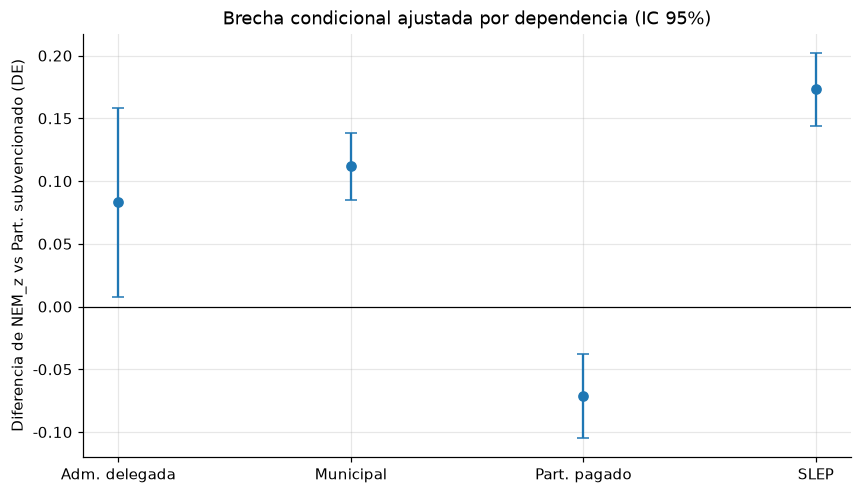

In [6]:
# 4.b Brecha condicional ajustada por dependencia (Part. subvencionado = 0),
# con IC 95%.
dependencias = coeficientes(modelo).filter(like='dependencia', axis=0)
nombres = (dependencias.index.str.removeprefix('dependencia[T.')
           .str.removesuffix(']'))
error = [dependencias['coef'] - dependencias['ic95_inf'],
         dependencias['ic95_sup'] - dependencias['coef']]
fig, ax = plt.subplots()
ax.errorbar(nombres, dependencias['coef'], yerr=error, fmt='o', capsize=4)
ax.axhline(0, color='black', linewidth=0.8)
ax.set(title='Brecha condicional ajustada por dependencia (IC 95%)',
       ylabel='Diferencia de NEM_z vs Part. subvencionado (DE)')
mostrar('mod_4b_dependencia')

## 5. Composición socioeconómica del colegio

Se agrega el **decil medio del colegio** como variable a nivel colegio. Si la brecha
de SLEP se debiera a que sus colegios atienden a estudiantes de menor nivel
socioeconómico, su coeficiente debería acercarse a 0 al incluir esta variable.

In [7]:
# 5.a Mismo modelo con el decil medio del colegio: compara los coeficientes
# de dependencia con y sin composición.
con_composicion = smf.mixedlm(FORMULA + ' + decil_medio_colegio', datos,
                              groups=datos['RBD']).fit()
print(f'Convergió: {con_composicion.converged}')
comparacion = pd.DataFrame({
    'sin composición': coeficientes(modelo)['coef'],
    'con composición': coeficientes(con_composicion)['coef'],
}).filter(like='dependencia', axis=0)
display(comparacion.round(3))
print('Decil medio del colegio:')
display(coeficientes(con_composicion).loc[['decil_medio_colegio']].round(3))
print(f'ICC residual con composición: {icc(con_composicion):.3f}')

Convergió: True


,sin composición,con composición
dependencia[T.Adm. delegada],0.083,0.067
dependencia[T.Municipal],0.112,0.076
dependencia[T.Part. pagado],-0.071,0.093
dependencia[T.SLEP],0.173,0.138


Decil medio del colegio:


,coef,ic95_inf,ic95_sup,valor_p
decil_medio_colegio,-0.049,-0.061,-0.037,0.0


ICC residual con composición: 0.136


In [8]:
# 5.b VIF con el decil medio del colegio: cuánto se solapa la composición
# socioeconómica con la dependencia.
vif_composicion = vif(VARIABLES + ' + decil_medio_colegio')
display(vif_composicion.filter(regex='dependencia|decil_medio')
        .to_frame('VIF'))

,VIF
dependencia[T.Adm. delegada],1.15
dependencia[T.Municipal],1.24
dependencia[T.Part. pagado],2.93
dependencia[T.SLEP],1.10
decil_medio_colegio,3.75


**Interpretación.** A igual PAES y características del estudiante, los colegios con
estudiantes de mayor nivel socioeconómico tienen algo **menos** NEM: -0,05 DE por
cada punto de decil medio. Al incluir la composición:

- **SLEP** baja de +0,17 a +0,14: una parte pequeña de su brecha (cerca de un 20%) se
  asocia a que atiende a estudiantes de menor nivel socioeconómico, pero la mayor
  parte se mantiene.
- **Part. pagado** cambia de signo (de -0,07 a +0,09). **No debe interpretarse**: sus
  colegios tienen un decil medio cercano a 8, mientras el resto está cerca de 4, y
  solo 2 colegios que no son Part. pagado tienen decil medio de 8 o más. "Part. pagado
  a igual composición" es una extrapolación, y el VIF de Part. pagado (2,93) y del
  decil medio (3,75) sube por ese solapamiento.
- SLEP y Municipal tienen la misma composición (decil medio 3,85 y 3,84), así que
  su comparación no depende de esta variable (sección 7).

## 6. Verificación: pendiente aleatoria de PAES

Se estima una versión en la que la pendiente de `PAES_z` también varía entre
colegios. Si los coeficientes de dependencia casi no cambian, el intercepto
aleatorio basta para la pregunta del proyecto. `statsmodels` avisa que la solución
podría estar "en el borde del espacio de parámetros", pero las varianzas estimadas del
intercepto y de la pendiente son mayores que 0 (ver abajo), así que la solución no
está en el borde y el aviso se oculta.

In [9]:
# 6. Intercepto y pendiente de PAES_z aleatorios por colegio.
with warnings.catch_warnings():
    warnings.simplefilter('ignore')  # aviso de borde (ver el texto)
    pendiente = smf.mixedlm(FORMULA, datos, groups=datos['RBD'],
                            re_formula='~PAES_z').fit()
print(f'Convergió: {pendiente.converged}')

var_intercepto = pendiente.cov_re.iloc[0, 0]
var_pendiente = pendiente.cov_re.iloc[1, 1]
covarianza = pendiente.cov_re.iloc[0, 1]
correlacion = covarianza / (var_intercepto * var_pendiente) ** 0.5
print(f'Varianza del intercepto: {var_intercepto:.4f} | de la pendiente: '
      f'{var_pendiente:.4f} | correlación: {correlacion:.2f}')
comparacion['pendiente aleatoria'] = coeficientes(pendiente)['coef']
display(comparacion.round(3))

Convergió: True
Varianza del intercepto: 0.0974 | de la pendiente: 0.0091 | correlación: -0.41


,sin composición,con composición,pendiente aleatoria
dependencia[T.Adm. delegada],0.083,0.067,0.128
dependencia[T.Municipal],0.112,0.076,0.122
dependencia[T.Part. pagado],-0.071,0.093,-0.126
dependencia[T.SLEP],0.173,0.138,0.183


## 7. Hipótesis 1: ¿SLEP mantiene una brecha positiva?

*A igual PAES, decil socioeconómico y sexo, ¿los estudiantes de SLEP tienen más NEM?*
Se reporta SLEP respecto de Part. subvencionado (la referencia) y respecto de
Municipal, porque SLEP surge de traspasos desde municipios.

In [10]:
# 7. Coeficiente de SLEP y contraste SLEP - Municipal en los tres modelos.
SLEP = 'dependencia[T.SLEP]'
MUNICIPAL = 'dependencia[T.Municipal]'
modelos = {'sin composición': modelo, 'con composición': con_composicion,
           'pendiente aleatoria': pendiente}
filas = {}
for nombre, resultado in modelos.items():
    slep = coeficientes(resultado).loc[SLEP]
    dif = contraste(resultado, SLEP, MUNICIPAL)
    filas[nombre] = {
        'SLEP vs Part. subv.': slep['coef'],
        'IC 95% inf.': slep['ic95_inf'], 'IC 95% sup.': slep['ic95_sup'],
        'SLEP - Municipal': dif['diferencia'],
        'IC 95% inf. ': dif['ic95_inf'], 'IC 95% sup. ': dif['ic95_sup'],
    }
display(pd.DataFrame(filas).T.round(3))

,SLEP vs Part. subv.,IC 95% inf.,IC 95% sup.,SLEP - Municipal,IC 95% inf.,IC 95% sup.
sin composición,0.173,0.144,0.202,0.061,0.045,0.078
con composición,0.138,0.108,0.168,0.062,0.045,0.079
pendiente aleatoria,0.183,0.154,0.212,0.061,0.045,0.078


**Resultado.** La Hipótesis 1 se sostiene en las tres especificaciones:

- **SLEP frente a Part. subvencionado:** +0,17 DE (IC 95%: 0,14 a 0,20); +0,14 (0,11 a
  0,17) con la composición del colegio y +0,18 (0,15 a 0,21) con pendiente
  aleatoria. Ningún intervalo incluye el 0.
- **SLEP frente a Municipal:** +0,06 DE (IC 95%: 0,05 a 0,08) en los tres modelos.

**En lenguaje simple:** entre estudiantes con la misma PAES, el mismo decil de
ingreso, el mismo sexo, la misma modalidad y el mismo año, los de colegios SLEP
tienen en promedio un NEM 0,17 DE mayor que los de Part. subvencionado (unos 24
puntos NEM, con una DE del NEM cercana a 140 puntos) y 0,06 DE mayor que los de
colegios municipales (unos 9 puntos). Es una **asociación**, no un efecto de la
administración SLEP: el modelo no permite saber si se debe a las prácticas de
evaluación, a qué estudiantes llegan a esos colegios o a los traspasos desde los
municipios.

## 8. Síntesis

**Colinealidad.** Todos los VIF están bajo 2,2: no se ajustó nada. Al agregar la
composición del colegio, el VIF de Part. pagado y del decil medio sube a 2,93 y
3,75.

**ICC.**

| Medida | Valor |
|---|---:|
| Proporción de varianza entre colegios (EDA, aproximación) | 0,14 |
| ICC del modelo nulo de la brecha condicional (exacto) | 0,130 |
| ICC residual del modelo completo | 0,139 |
| ICC residual con composición del colegio | 0,136 |

El ICC residual puede ser mayor que el nulo porque los controles (PAES, sexo,
decil, modalidad) explican sobre todo variación **dentro** de los colegios: la
varianza dentro baja de 0,626 a 0,592, mientras la varianza entre colegios casi no
cambia (0,094 a 0,096), así que la proporción entre colegios sube. Los dos ICC no
son directamente comparables: cada uno es una proporción de una varianza total
distinta (la brecha condicional en el modelo nulo y lo que queda del NEM_z después
de los controles en el modelo completo).

El EDA lo sobreestimaba levemente, como se esperaba. Cerca del 13% de la variación
de la brecha condicional ocurre entre colegios, y esa proporción casi no cambia al
controlar por las características del estudiante, la dependencia y la composición:
las diferencias entre colegios no se explican por esas variables.

**Modelo jerárquico** (`NEM_z ~ PAES_z * electiva + año + dependencia + decil + sexo
+ modalidad + (1 | RBD)`):

- **Brecha condicional ajustada por dependencia** (respecto de Part. subvencionado):
  SLEP +0,17, Municipal +0,11, Adm. delegada +0,08 y Part. pagado -0,07.
- **Sexo:** a igual PAES y colegio, las mujeres tienen 0,38 DE más de NEM (unos 53
  puntos), igual que en el EDA. Es la diferencia más grande del modelo.
- **Modalidad:** técnico-profesional -0,19 DE, más negativa que en el EDA (-0,05).
  Se confunde con Adm. delegada, cuyos estudiantes son todos técnico-profesionales
  (ver `05_sensibilidad_y_sintesis`).
- **Decil:** diferencias pequeñas respecto del decil 1 (entre +0,02 y +0,08).
- **Pendiente de la PAES:** 0,54 en Ambas y en Historia y 0,62 en Ciencias.
- **Año:** casi 0, como se esperaba, porque las variables están estandarizadas por
  año.

**Pendiente aleatoria.** La pendiente de la PAES varía entre colegios (DE de 0,10
alrededor de 0,54-0,62; correlación con el intercepto de -0,41: los colegios con más
NEM a igual PAES tienen una pendiente algo más plana). El coeficiente de SLEP casi no
cambia (+0,18), así que el intercepto aleatorio basta para la pregunta del proyecto.

**Hipótesis 1.** Se sostiene: a igual PAES, decil, sexo, modalidad y año, SLEP
mantiene una brecha positiva frente a Part. subvencionado (+0,14 a +0,18 según la
especificación) y frente a Municipal (+0,06). Es una asociación, no un efecto causal.

**Decisiones.** El modelo principal es el de intercepto aleatorio sin composición
(la especificación acordada). El modelo con composición se usa como sensibilidad
para SLEP y Municipal; el coeficiente de Part. pagado con composición no se
interpreta. El acceso por etapas está en `04_acceso_por_etapas` y la
sensibilidad en `05_sensibilidad_y_sintesis`.